/home/maqs/projects/thermal_h2/problems/.conda/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


Text(0.5, 1.0, 'z = 2.5 (mid reservoir)')

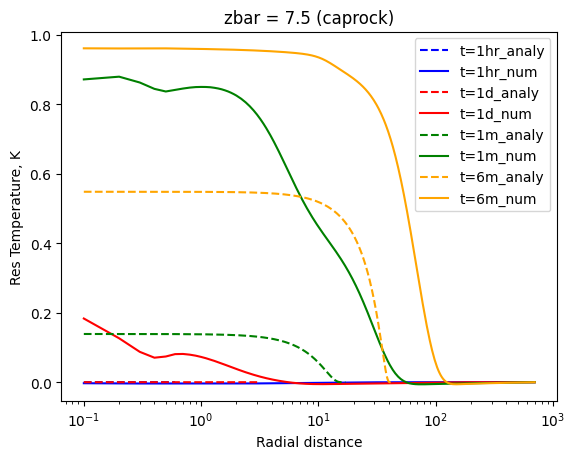

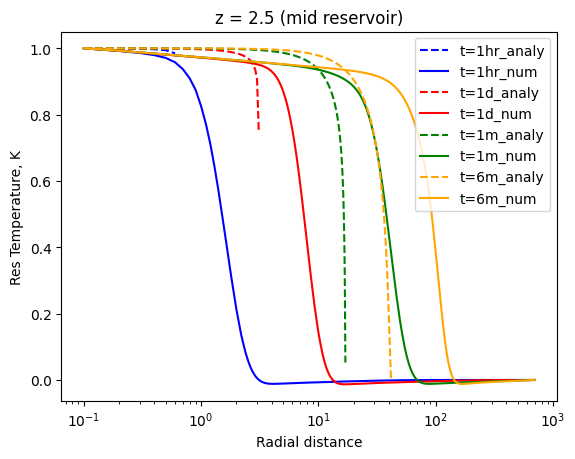

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pickle
from scipy.special import erfc
pi = np.pi
def HeavisideFunc(argt):
    return np.where(argt <= 0, 0, 1)

# Create subplots for each variable
   # fig, axes = plt.subplots(3, 1, figsize=(10, 15))
    
# Read CSV file into a pandas DataFrame
df1 = pd.read_csv(r'withcaprock_ny20_csv_ptsuss_0003.csv')
df2 = pd.read_csv(r'withcaprock_ny20_csv_ptsuss_0008.csv')
df3 = pd.read_csv(r'withcaprock_ny20_csv_ptsuss_0014.csv')
df4 = pd.read_csv(r'withcaprock_ny20_csv_ptsuss_0028.csv')

df1r = pd.read_csv(r'withcaprock_ny20_csv_ptsuss3_0003.csv')
df2r = pd.read_csv(r'withcaprock_ny20_csv_ptsuss3_0008.csv')
df3r = pd.read_csv(r'withcaprock_ny20_csv_ptsuss3_0014.csv')
df4r = pd.read_csv(r'withcaprock_ny20_csv_ptsuss3_0028.csv')

x_coordinate = df4.iloc[:, 3]  # 4th column
r = x_coordinate
#num_elements = x_coordinate.shape[0]
#pgas_initial = np.full(num_elements, 18.3e6)


#t =  [3600,86400,2.592e6,1.577e7]   #seconds
#t = 1.577e7
t1 = 3600
t2 = 86400
t3 = 2.592e6
t4 = 1.577e7

T0 = 331 #res temp
Ti = 294   # inj temp
  
temp_t1 = df1.iloc[:, 2] 
temp_t2 = df2.iloc[:, 2] 
temp_t3 = df3.iloc[:, 2] 
temp_t4 = df4.iloc[:, 2] 

temp_t1r = df1r.iloc[:, 2] 
temp_t2r = df2r.iloc[:, 2] 
temp_t3r = df3r.iloc[:, 2] 
temp_t4r = df4r.iloc[:, 2] 

temp_t1_bar = (temp_t1 - T0)/(Ti-T0)
temp_t2_bar = (temp_t2 - T0)/(Ti-T0)
temp_t3_bar = (temp_t3 - T0)/(Ti-T0)
temp_t4_bar = (temp_t4 - T0)/(Ti-T0)

temp_t1r_bar = (temp_t1r - T0)/(Ti-T0)
temp_t2r_bar = (temp_t2r - T0)/(Ti-T0)
temp_t3r_bar = (temp_t3r - T0)/(Ti-T0)
temp_t4r_bar = (temp_t4r - T0)/(Ti-T0)

# Example usage:

Q = 0.00606  # injection flow rate, m3/s Replace with the desired value for Q

rho_g = 516.48
C_g = 2920.5 # specific heat capacity of gas
rhocg = rho_g * C_g

rho_1 = 2350 
C_1 = 1100 # specific heat capacity of res
rho_2 = 2773.4 
C_2 = 829 # specific heat capacity of caprock
rhoc1 = rho_1 * C_1
rhoc2 = rho_2 * C_2
 

lambda2z = 1.600
ymin = 0
ymax = 10
h = ymax - ymin
z = 7.5 #7.5 #h/2 #zbar =0 

#Tbar = (temp_t1 - T0)/(Ti - T0)
zbar = (2*z/h)-1 # for z>=h/2

tow1 = (4 * lambda2z * t1 / (h**2 * rhoc1))
tow2 = (4 * lambda2z * t2 / (h**2 * rhoc1))
tow3 = (4 * lambda2z * t3 / (h**2 * rhoc1))
tow4 = (4 * lambda2z * t4 / (h**2 * rhoc1))

eta = (4 * lambda2z * pi * r**2) / (h * rhocg * Q)
teta = rhoc2/rhoc1

T2bar_1 = erfc((eta + zbar) / (2 * np.sqrt((tow1 - eta) * teta))) * HeavisideFunc(tow1 - eta)
T2bar_2 = erfc((eta + zbar) / (2 * np.sqrt((tow2 - eta) * teta))) * HeavisideFunc(tow2 - eta)
T2bar_3 = erfc((eta + zbar) / (2 * np.sqrt((tow3 - eta) * teta))) * HeavisideFunc(tow3 - eta)
T2bar_4 = erfc((eta + zbar) / (2 * np.sqrt((tow4 - eta) * teta))) * HeavisideFunc(tow4 - eta)

T1bar_1 = erfc((eta) / (2 * np.sqrt((tow1 - eta) * teta))) * HeavisideFunc(tow1 - eta)
T1bar_2 = erfc((eta) / (2 * np.sqrt((tow2 - eta) * teta))) * HeavisideFunc(tow2 - eta)
T1bar_3 = erfc((eta) / (2 * np.sqrt((tow3 - eta) * teta))) * HeavisideFunc(tow3 - eta)
T1bar_4 = erfc((eta) / (2 * np.sqrt((tow4 - eta) * teta))) * HeavisideFunc(tow4 - eta)

T2_1 = T0+(T2bar_1*(Ti-T0))
T2_2 = T0+(T2bar_2*(Ti-T0))
T2_3 = T0+(T2bar_3*(Ti-T0))
T2_4 = T0+(T2bar_4*(Ti-T0))

T1_1 = T0+(T1bar_1*(Ti-T0))
T1_2 = T0+(T1bar_2*(Ti-T0))
T1_3 = T0+(T1bar_3*(Ti-T0))
T1_4 = T0+(T1bar_4*(Ti-T0))

#plot OB Temp
plt.figure(1)
plt.plot(r, T2bar_1, label='t=1hr_analy',linestyle='dashed', color='blue')
plt.plot(r, temp_t1_bar, label='t=1hr_num',linestyle='solid', color='blue')
plt.plot(r, T2bar_2, label='t=1d_analy',linestyle='dashed', color='red')
plt.plot(r, temp_t2_bar, label='t=1d_num',linestyle='solid', color='red')
plt.plot(r, T2bar_3, label='t=1m_analy',linestyle='dashed', color='green')
plt.plot(r, temp_t3_bar, label='t=1m_num',linestyle='solid', color='green')
plt.plot(r, T2bar_4, label='t=6m_analy',linestyle='dashed', color='orange')
plt.plot(r, temp_t4_bar, label='t=6m_num',linestyle='solid', color='orange')
plt.legend(loc="upper right")
# convert y-axis to Logarithmic scale
plt.xscale("log")
# Add labels and title
plt.xlabel('Radial distance')
plt.ylabel('Res Temperature, K')
plt.title('zbar = 7.5 (caprock)')
#plt.ylim(0,0.001)


#plot Res Temp
plt.figure(2)
plt.plot(r, T1bar_1, label='t=1hr_analy',linestyle='dashed', color='blue')
plt.plot(r, temp_t1r_bar, label='t=1hr_num',linestyle='solid', color='blue')
plt.plot(r, T1bar_2, label='t=1d_analy',linestyle='dashed', color='red')
plt.plot(r, temp_t2r_bar, label='t=1d_num',linestyle='solid', color='red')
plt.plot(r, T1bar_3, label='t=1m_analy',linestyle='dashed', color='green')
plt.plot(r, temp_t3r_bar, label='t=1m_num',linestyle='solid', color='green')
plt.plot(r, T1bar_4, label='t=6m_analy',linestyle='dashed', color='orange')
plt.plot(r, temp_t4r_bar, label='t=6m_num',linestyle='solid', color='orange')
plt.legend(loc="upper right")
# convert y-axis to Logarithmic scale
plt.xscale("log")
# Add labels and title
plt.xlabel('Radial distance')
plt.ylabel('Res Temperature, K')
plt.title('z = 2.5 (mid reservoir)')
#plt.ylim(0,0.001)




